# OpenMC → plot tracks

Reads the OpenMC `tracks.h5` file and plot some tracks for reference.

In [1]:
import os
import sys
import glob
import h5py
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from matplotlib.colors import LogNorm

In [2]:
# Make the src/ folder importable
sys.path.append(os.path.abspath("/Users/loren/WORKSPACE/PHOTON/verification-and-validation/3-coupling-OpenMC-MPPost/src"))

import openmc
from TrackAnalyzer import build_analyzer, describe_history, particle_name

In [ ]:
# ================================ CONFIGURATION ================================
PARTICLE         = "photon"          # "neutron" | "photon"  (never both)
DETECTOR         = "nai"         # key of DETECTOR_LIBRARY
DETECTOR_MAT_IDS = [99]               # OpenMC material ID(s) of the detector


BASE_DIR   = "/Users/loren/WORKSPACE/PHOTON/verification-and-validation/3-coupling-OpenMC-MPPost"
CASE = "sodium-iodide/137Cs"
TRACK_DIR  = "/Volumes/PortableSSD/DATA/2026/UM-OPENMC-PYMPPOST-METHODOLOGY/" + CASE
TRACK_FILE = "OpenMC_tracks_1.0E5.h5"

# Incident energy below which events are not written [eV].
# For photons keep it >= the OpenMC photon energy cutoff (default 1 keV).
E_THRESHOLD_EV = {"neutron": 1e1, "photon": 1e3}

MAX_RESIDUAL   = 0.05     # neutrons: tolerance on |predicted - measured| E'/E
WRITE_COHERENT = False    # photons: write coherent scattering events (Edep = 0)
N_INSPECT      = 10       # number of initial histories printed in verbose mode

# Detector descriptions
#   neutron_targets: nuclide -> atomic weight ratio (A) and ZAID written in the file
#   photon_zaid    : representative ZAID written for photon interactions
DETECTOR_LIBRARY = {
    "stilbene": {
        "neutron_targets": {"H-1":  {"A": 0.99917, "zaid": 1001},
                            "C-12": {"A": 11.8969, "zaid": 6000}},
        "photon_zaid": 6000,
    },

    "helium4": {
        "neutron_targets": {"He-4":  {"A":3.968, "zaid": 2004}},
        "photon_zaid": 6000,
    },    

    "nai": {
    "neutron_targets": {"Na-23": {"A": 22.9898, "zaid": 11023},
                        "I-127": {"A": 126.9045, "zaid": 53127}},
    "photon_zaid": 53000,
},
}
# ===============================================================================

RESULTS_DIR = os.path.join(BASE_DIR, "results", CASE)
TRACK_PATH  = os.path.join(TRACK_DIR, TRACK_FILE)
DET         = DETECTOR_LIBRARY[DETECTOR]

# Count the histories without loading the track data
with h5py.File(TRACK_PATH, "r") as fh:
    SOURCE_PARTICLES = sum(1 for key in fh.keys() if key.startswith("track_"))
print(f"Total source particles: {SOURCE_PARTICLES / 1e5}E5")


Total source particles: 4.0E5


# Track visualization

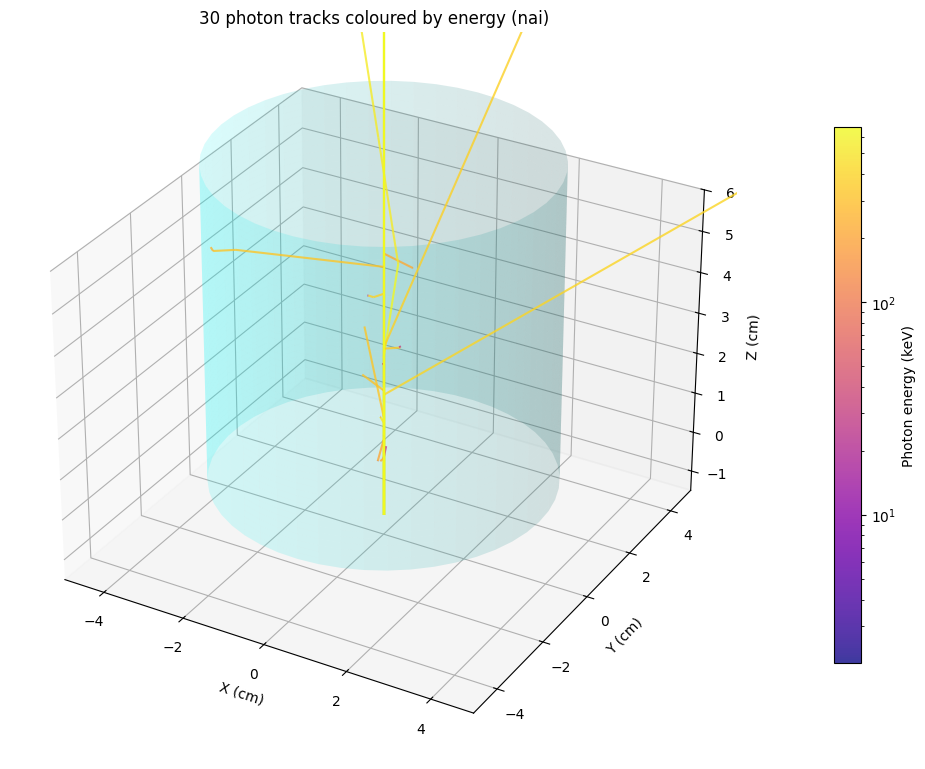

In [5]:
track_files = glob.glob(TRACK_PATH)

# 1. Set up the 3D plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# 2. Draw the Stilbene Cylinder
radius = 7.62 / 2
length = 7.62
theta = np.linspace(0, 2 * np.pi, 50)
z_cyl = np.linspace(0, length, 50)

theta_grid, Z_grid = np.meshgrid(theta, z_cyl)
X_grid = radius * np.cos(theta_grid)
Y_grid = radius * np.sin(theta_grid)

ax.plot_surface(X_grid, Y_grid, Z_grid, alpha=0.15, color='cyan', edgecolor='none')

# 3. Lists to hold all line segments and their corresponding energies
segments = []
energies = []
TRACK_COUNT = 0
TRACK_THRESHOLD = 30 # number of tracks to visualize

# Sort tracks in the same order as OpenMC
def _identifier(dset_name):
    _, batch, gen, particle = dset_name.split('_')
    return (int(batch), int(gen), int(particle))

# 4. Parse track files and break them into segments (Memory-Optimized)
for track_file in track_files:
    
    with h5py.File(track_file, 'r') as fh:
        # Grab only the track keys and sort them
        dataset_names = sorted([k for k in fh.keys() if k.startswith('track_')], key=_identifier)
        
        for dset_name in dataset_names:
            
            # Stop reading the HDF5 file once enough tracks are collected
            if TRACK_COUNT >= TRACK_THRESHOLD:
                break
                
            # LAZY LOAD: Build the Python object for just this one history
            dset = fh[dset_name]
            track = openmc.Track(dset)
            
            for p_track in track.particle_tracks:
                # Keep only the particle selected in the configuration
                if particle_name(p_track.particle) != PARTICLE:
                    continue
                
                # Increment count and check threshold again
                TRACK_COUNT += 1
                if TRACK_COUNT > TRACK_THRESHOLD:
                    break 
                
                # Extract positions and energies
                r = p_track.states['r']
                x, y, z = r['x'], r['y'], r['z']
                E = p_track.states['E'] / 1E3 # Energy converted to keV
                
                # Stack coordinates into an (N, 3) array
                pts = np.vstack([x, y, z]).T
                
                # We need at least 2 points to draw a line segment
                if len(pts) < 2:
                    continue
                
                # Chop the track into individual (Start -> End) segments
                for i in range(len(pts) - 1):
                    segments.append([pts[i], pts[i+1]])
                    
                    # Map this segment to the energy at the start of the step
                    energies.append(max(E[i], 1e-5))

    # Break out of the outer file loop if we hit the threshold
    if TRACK_COUNT >= TRACK_THRESHOLD:
        break

# 5. Create a Line3DCollection colored by energy
if segments:
    # We use LogNorm because energies drop from ~10^6 eV to ~10^-1 eV
    lc = Line3DCollection(segments, cmap='plasma', alpha=0.8, linewidth=1.5, norm=LogNorm())
    lc.set_array(np.array(energies))
    ax.add_collection3d(lc)
    
    # Attach the colorbar to the figure
    cbar = fig.colorbar(lc, ax=ax, shrink=0.7, pad=0.1)
    cbar.set_label(f'{PARTICLE.capitalize()} energy (keV)')

# 6. Format the plot
ax.set_xlabel('X (cm)')
ax.set_ylabel('Y (cm)')
ax.set_zlabel('Z (cm)')
ax.set_title(f'{TRACK_THRESHOLD} {PARTICLE} tracks coloured by energy ({DETECTOR})')

ax.set_xlim([-5, 5])
ax.set_ylim([-5, 5])
ax.set_zlim([-1.5, 6])


plt.tight_layout()
plt.show()